In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.manifold import trustworthiness
from factor_analyzer import calculate_bartlett_sphericity, calculate_kmo

In [2]:
data = pd.read_pickle('norm_data.pkl')
data.head()

,Cреднеспис.числ.работн,k1,k2,k3,k4,k4_new,k5,k6,k7,k8,...,k12,k13,k14,k15,k16,k17,k18,k19,k20,Year
0,6095.0,0.403809,0.503518,0.548820,0.328302,NaN,0.330954,0.475458,0.833823,0.675877,...,0.451272,0.309298,0.359411,0.340312,0.459953,1.000000,0.554562,0.497247,0.479035,5.0
1,255.0,0.591695,0.653597,0.632007,0.763404,NaN,0.169329,0.543158,0.421875,0.877837,...,0.471764,0.330484,0.592674,0.566433,0.490934,1.000000,0.678800,0.510526,0.458055,5.0
2,114.0,0.300968,0.462057,0.341906,0.000000,NaN,0.379270,0.893999,1.000000,0.645891,...,0.502503,0.083725,0.220906,0.402367,1.000000,0.558105,0.000000,0.371303,0.399927,5.0
3,365.0,1.000000,1.000000,1.000000,0.902599,NaN,0.126387,0.311175,0.433346,0.890587,...,0.564472,1.000000,1.000000,0.942774,0.418881,0.546973,0.854628,1.000000,1.000000,5.0
4,168.0,0.555295,0.464936,0.620328,0.709942,NaN,0.235475,1.000000,0.927524,0.808497,...,0.407338,0.231825,0.403838,0.317202,0.420597,0.496557,0.516877,0.414231,0.426759,5.0


In [3]:
def data_filter(data):
    return data[[col for col in data.columns if col.startswith("k") and col[1].isdigit()]]

In [4]:
data_x = data_filter(data)
data_mod = data_x.drop(labels = ["k8", "k4_new"], axis = 1)

In [5]:
data_mod.to_pickle('data_mod.pkl')

In [6]:
chi_square, p_value = calculate_bartlett_sphericity(data_mod)

In [7]:
kmo_per_var, kmo_total = calculate_kmo(data_mod)

C:\apps\anaconda3\Lib\site-packages\factor_analyzer\utils.py:244: UserWarning: The inverse of the variance-covariance matrix was calculated using the Moore-Penrose generalized matrix inversion, due to its determinant being at or very close to zero.
  warnings.warn(


In [8]:
kmo_df = pd.DataFrame({
    'variable': data_mod.columns,
    'KMO': kmo_per_var
})

res = {
    'Bartlett chi-square': chi_square,
    'Bartlett p-value': p_value,
    'KMO overall': kmo_total
}

res_df = pd.DataFrame.from_dict(res, orient = 'index')

display(res_df)
display(kmo_df)

,0
Bartlett chi-square,41363.614213
Bartlett p-value,0.000000
KMO overall,0.732253


,variable,KMO
0,k1,0.818160
1,k2,0.828997
2,k3,0.753757
3,k4,0.724892
4,k5,0.618640
5,k6,0.821970
6,k7,0.901627
7,k9,0.665165
8,k10,0.524585
9,k11,0.750992


In [9]:
data_mod_tmp = data_mod.drop(labels = "k15", axis = 1)
_, kmo_total = calculate_kmo(data_mod_tmp)
print(kmo_total)

0.7370521061703315


C:\apps\anaconda3\Lib\site-packages\factor_analyzer\utils.py:244: UserWarning: The inverse of the variance-covariance matrix was calculated using the Moore-Penrose generalized matrix inversion, due to its determinant being at or very close to zero.
  warnings.warn(


In [10]:
data_mod_std = StandardScaler().fit_transform(data_mod)
pca = PCA()
pca.fit(data_mod_std)

PCA()

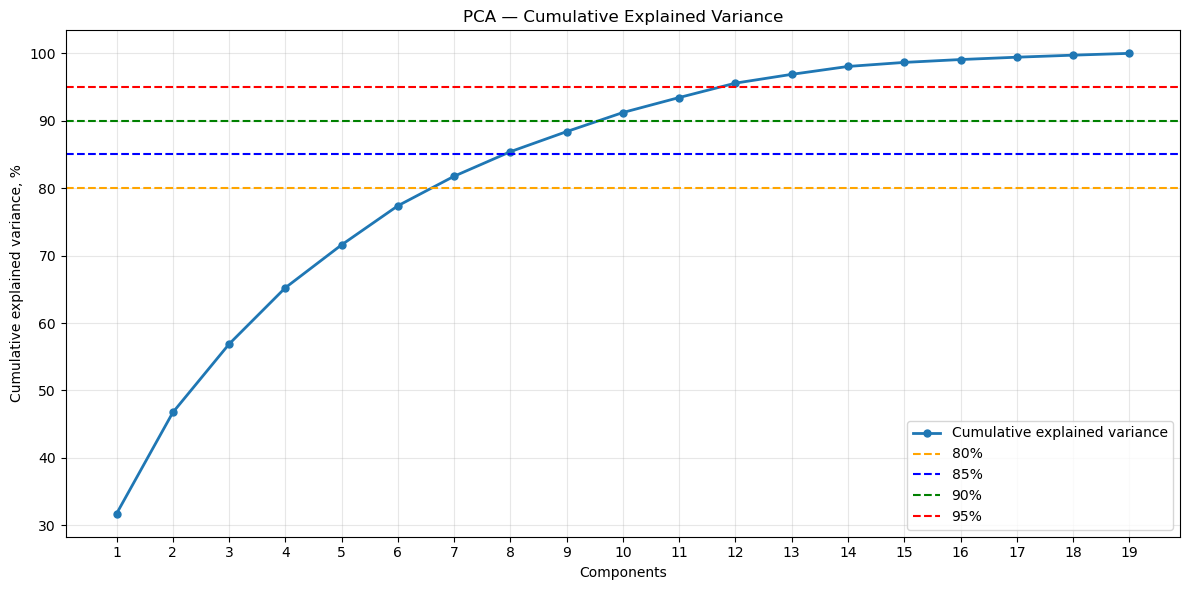

In [11]:
plt.figure(figsize=(12, 6))

plt.plot(
    range(1, len(pca.explained_variance_ratio_) + 1),
    np.cumsum(pca.explained_variance_ratio_ * 100),
    marker='o',
    linewidth = 2,
    markersize = 5,
    label = 'Cumulative explained variance'
)

plt.axhline(y = 80, color = 'orange', linestyle = '--', label = '80%')
plt.axhline(y = 85, color = 'blue', linestyle = '--', label = '85%')
plt.axhline(y = 90, color = 'green', linestyle = '--', label = '90%')
plt.axhline(y = 95, color = 'red', linestyle = '--', label = '95%')

plt.xlabel('Сomponents')
plt.ylabel('Cumulative explained variance, %')
plt.title('PCA — Cumulative Explained Variance')
plt.xticks(range(1, 20))

plt.grid(alpha = 0.3)
plt.legend()

plt.tight_layout()
plt.show()

In [12]:
components = [f"PC{i + 1}" for i in range(pca.n_components_)]
factor_weights = pca.components_.T * np.sqrt(pca.explained_variance_) 
pca_res = pd.DataFrame(factor_weights, columns = components, index = data_mod.columns)

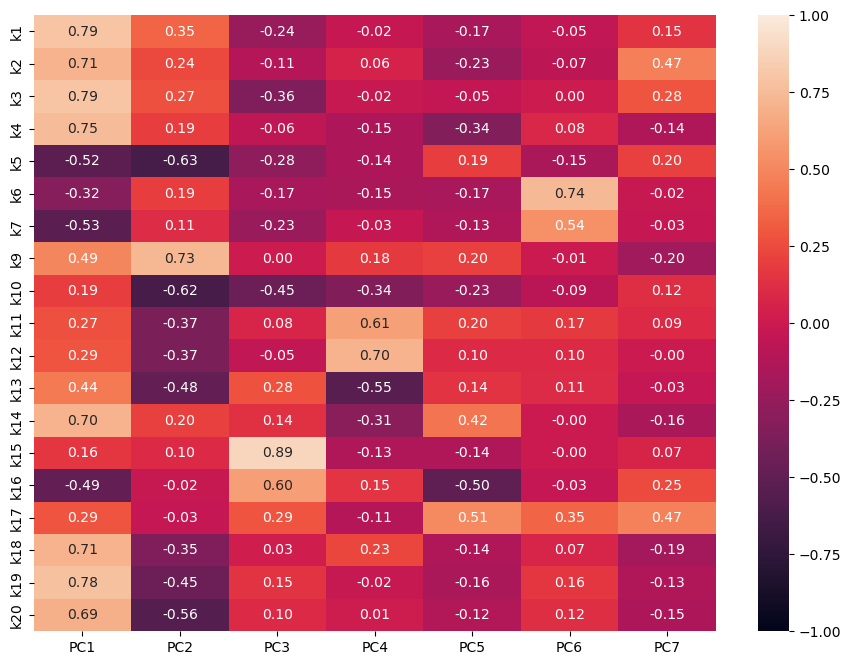

In [13]:
plt.figure(figsize = (11, 8))
sns.heatmap(pca_res.iloc[:, :7], annot = True, fmt = '.2f', vmin = -1, vmax = 1)
plt.show()

In [14]:
communality_data_7 = pd.DataFrame(pca_res.iloc[:, :7].pow(2).sum(axis = 1), columns = ["communality_7"], index = data_mod.columns)
communality_data_10 = pd.DataFrame(pca_res.iloc[:, :10].pow(2).sum(axis = 1), columns = ["communality_10"], index = data_mod.columns)
communality_data_8 = pd.DataFrame(pca_res.iloc[:, :8].pow(2).sum(axis = 1), columns = ["communality_8"], index = data_mod.columns)

communality_data = pd.concat([communality_data_7, communality_data_8, communality_data_10], axis = 1)
communality_data = communality_data.sort_values(by = "communality_7", ascending = False)
display(communality_data)

,communality_7,communality_8,communality_10
k16,0.935016,0.935188,0.935696
k3,0.907645,0.908348,0.919993
k19,0.891822,0.913990,0.940026
k9,0.885776,0.886045,0.892490
k5,0.867404,0.884185,0.939266
k15,0.862323,0.924061,0.929797
k1,0.861429,0.875469,0.877652
k14,0.851226,0.915706,0.936154
k20,0.850047,0.874637,0.918510
k2,0.848074,0.857707,0.903112


In [15]:
pca_scores = pd.DataFrame(pca.transform(data_mod_std), columns = components, index = data_mod.index) 
display(pca_scores)

,PC1,PC2,PC3,PC4,PC5,PC6,PC7,PC8,PC9,PC10,PC11,PC12,PC13,PC14,PC15,PC16,PC17,PC18,PC19
0,-1.066508,0.762699,-0.141745,0.264992,1.464999,1.244407,0.649448,2.797189,-0.011654,1.004332,-0.349422,-0.263508,0.271115,-0.217800,-0.155939,-0.103633,-0.154672,-0.256845,-0.199217
1,1.704670,2.237069,0.778398,0.422106,1.206881,0.580512,0.548768,1.952733,1.213281,-0.267221,-0.419407,0.682188,0.172077,-0.458740,-0.098467,-0.012973,0.221308,0.243297,0.241780
2,-4.899964,1.713098,0.479665,0.491059,-0.995486,1.366221,0.383209,1.060892,-1.038108,-0.023587,0.808137,-0.724461,-1.464413,0.098295,0.818621,-0.115850,-0.506768,-0.132754,-0.294196
3,6.725160,0.974619,0.940899,-0.971287,-0.861347,-0.314908,-0.168167,-0.668928,-1.331475,0.337828,0.240991,0.069028,-0.166503,-0.244026,-0.262422,-0.667262,0.237262,0.516689,0.074042
4,-1.026525,2.567463,-1.703974,-0.301933,-0.752769,1.934258,-1.444221,1.011064,0.146898,0.068141,-0.016937,-0.071530,0.292572,-0.092966,-0.105746,-0.091969,0.453012,0.048405,0.116360
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2690,2.504985,-1.428056,-0.757918,0.354694,-0.758185,0.614295,-0.819602,0.435004,0.164201,-0.456782,-0.320996,-1.018881,0.074098,0.428429,0.092550,-0.131945,0.010230,-0.325876,0.432769
2691,1.290049,-0.128703,0.197617,1.828965,0.728596,0.014849,-0.663116,-0.885684,0.756466,-0.153327,1.067548,-1.344941,0.197908,-0.279336,0.265588,-0.122022,0.226387,-0.291711,0.012942
2692,1.425174,-1.070317,1.495105,0.151909,0.858641,2.387387,-0.872042,-0.695874,-0.005822,0.831102,1.702234,-1.010380,0.257644,-0.037786,0.155538,0.179596,-0.298848,-0.425457,0.522845
2693,-0.048943,-0.878486,2.224340,1.744522,0.539247,-0.066405,-0.324895,-1.342043,0.853257,0.139933,1.263673,-0.589264,0.317921,0.080850,-0.280112,-0.176611,0.038827,-0.143692,-0.020219


In [16]:
weights = pca.explained_variance_ratio_[:7]
s = weights / weights.sum()

integr = (s * pca_scores.iloc[:, :7]).sum(axis = 1)
integr.describe()

count    2.695000e+03
mean     1.581913e-17
std      1.031737e+00
min     -2.607241e+00
25%     -7.547377e-01
50%     -1.249968e-01
75%      6.021246e-01
max      3.063324e+00
dtype: float64

In [23]:
trustworthiness(data_mod_std, pca.transform(data_mod_std)[:, :7], n_neighbors = 15)

np.float64(0.9882584460022441)